In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df_cleaned = df.copy()

In [11]:
df_cleaned["TotalCharges"] = (
    pd.to_numeric(
        df_cleaned["TotalCharges"].astype(str).str.strip(),
        errors="coerce"
    )
    .fillna(0)
)

In [12]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

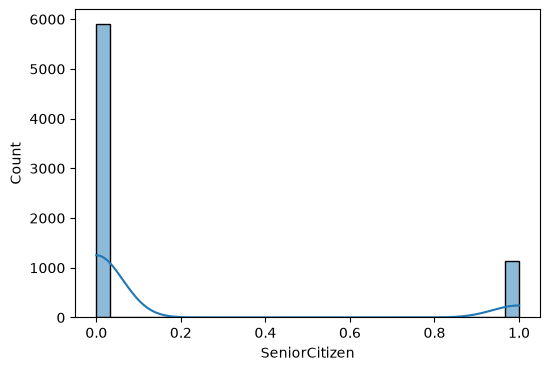

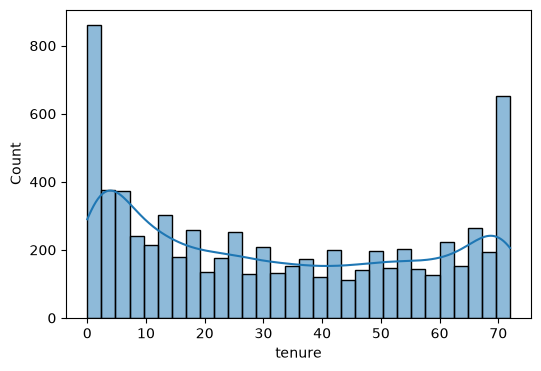

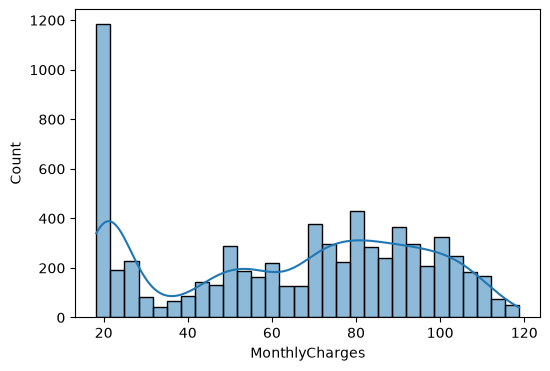

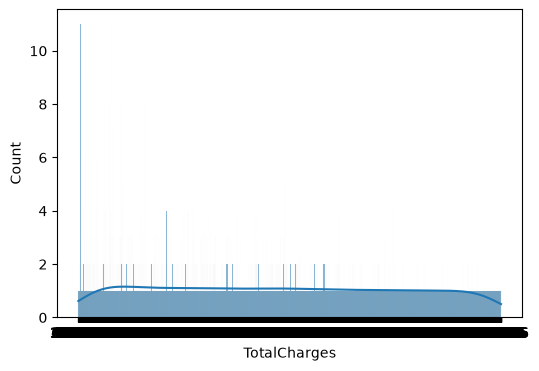

In [13]:
numric_col = ['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']

for col in numric_col:
    plt.figure(figsize=(6,4))
    sns.histplot(x = df[col],kde=True, bins=30)

In [14]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [15]:
df_cleaned.columns.to_list()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

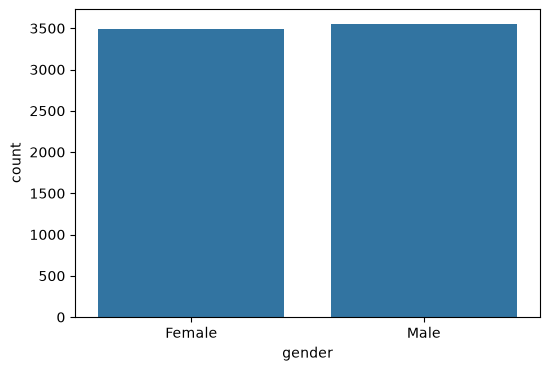

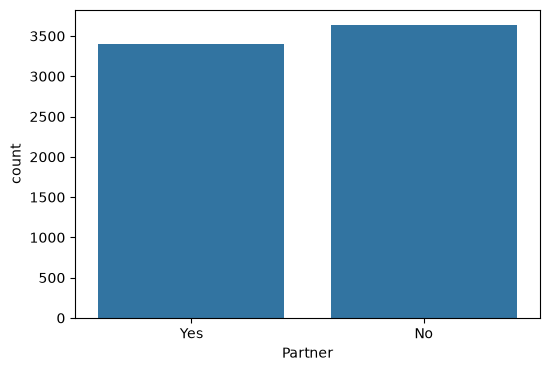

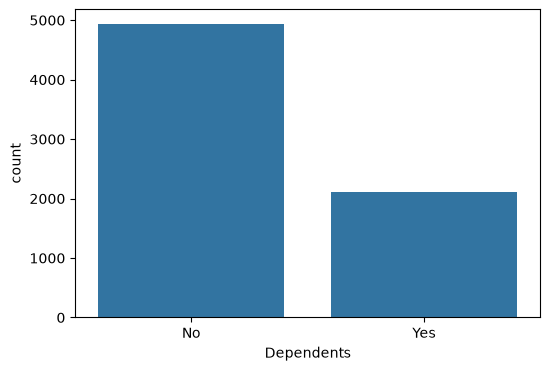

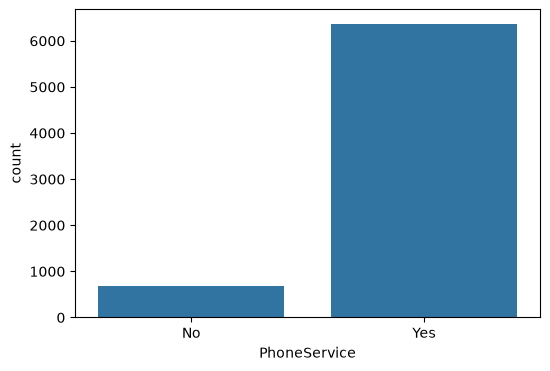

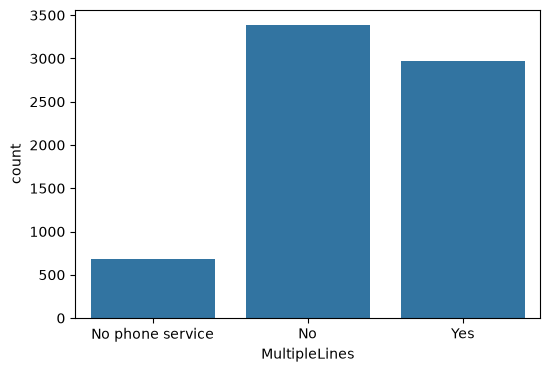

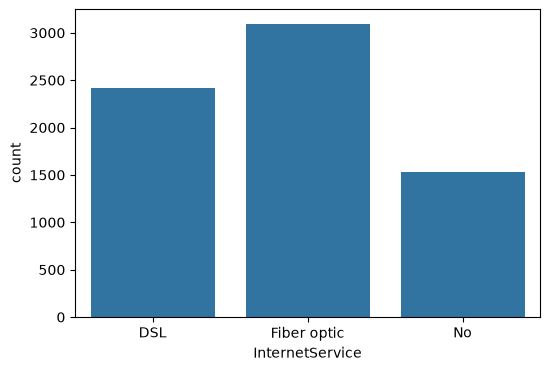

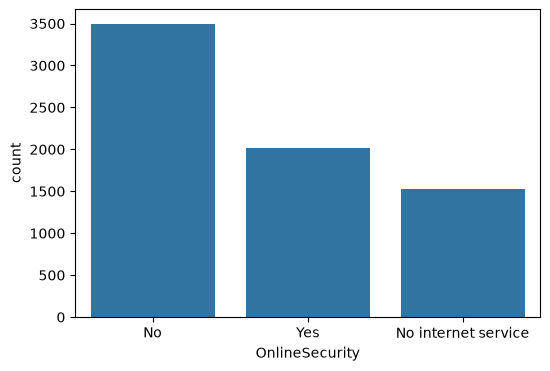

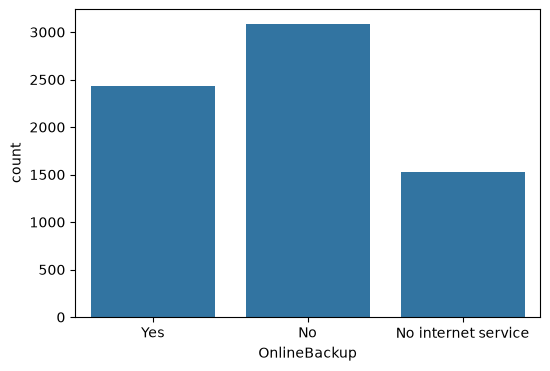

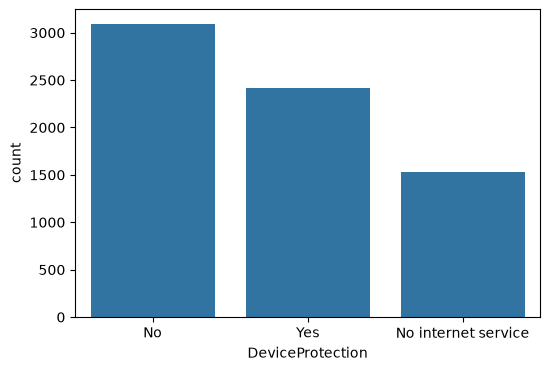

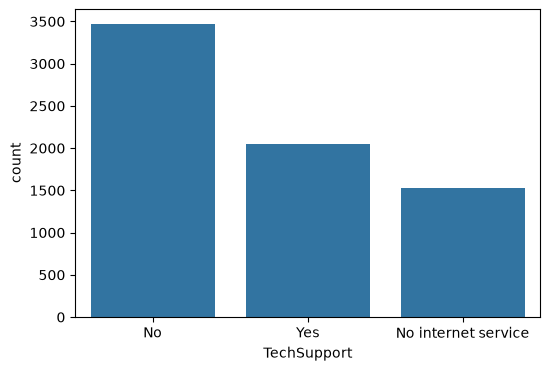

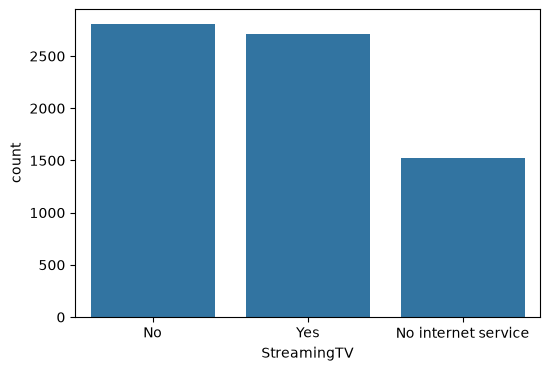

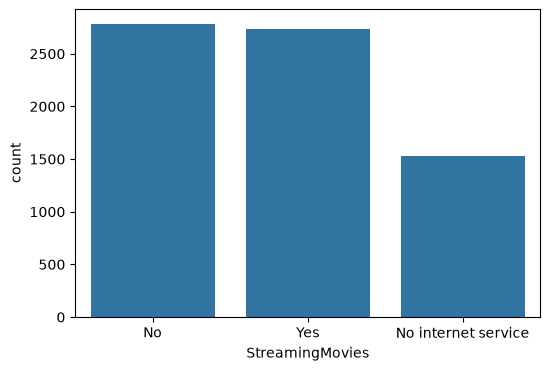

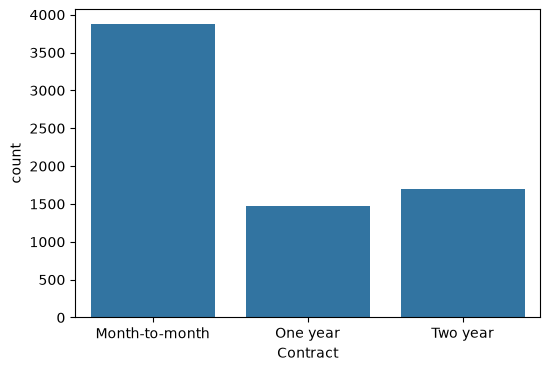

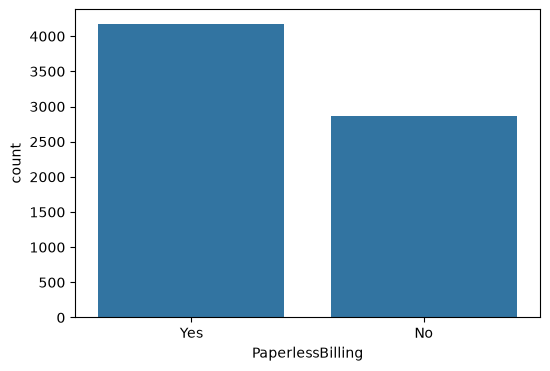

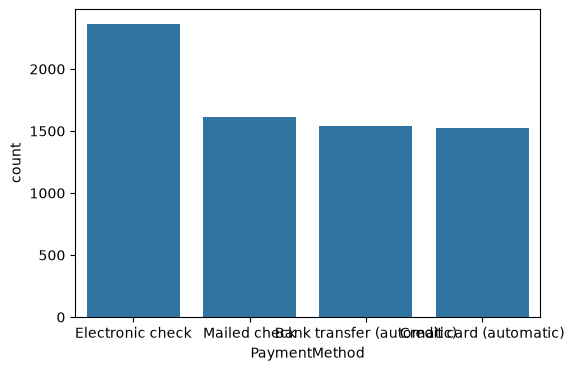

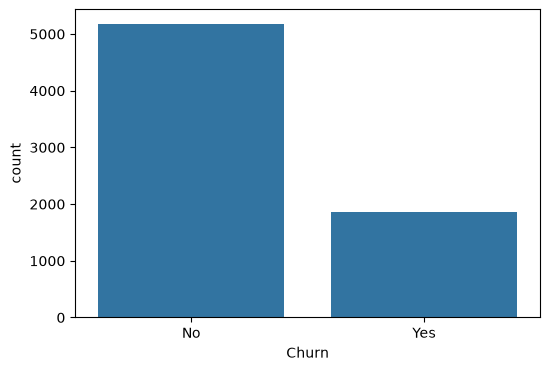

In [16]:
cat_col = ['gender','Partner','Dependents','PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod','Churn']


for col in cat_col:
    plt.figure(figsize=(6,4))
    sns.countplot(x = df_cleaned[col])


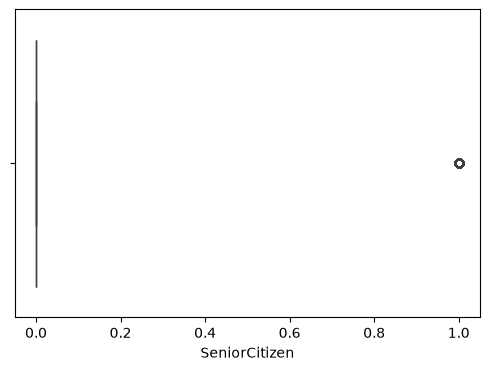

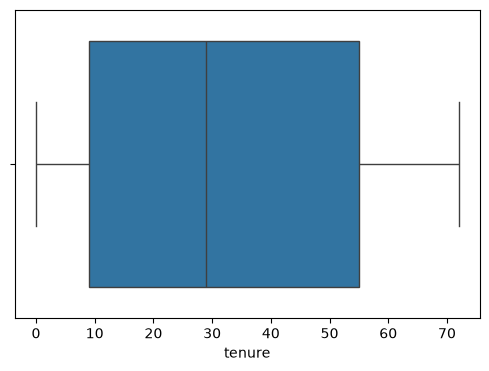

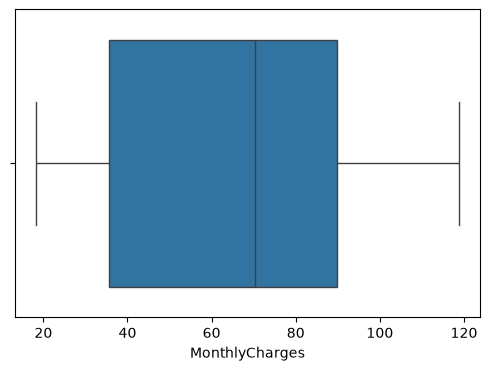

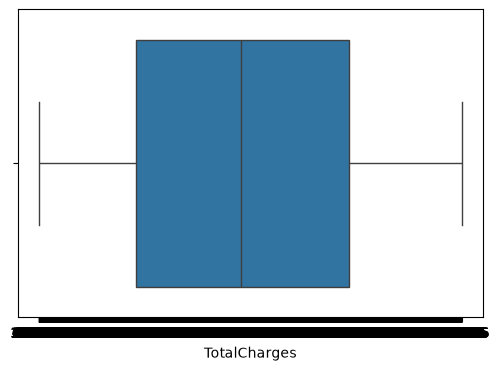

In [17]:
for col in numric_col:
    plt.figure(figsize=(6,4))
    sns.boxplot(x = df[col])

In [18]:
df_cleaned['Churn'] = df_cleaned['Churn'].map({'Yes':1,'No':0})

In [19]:
df_cleaned.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


<Axes: >

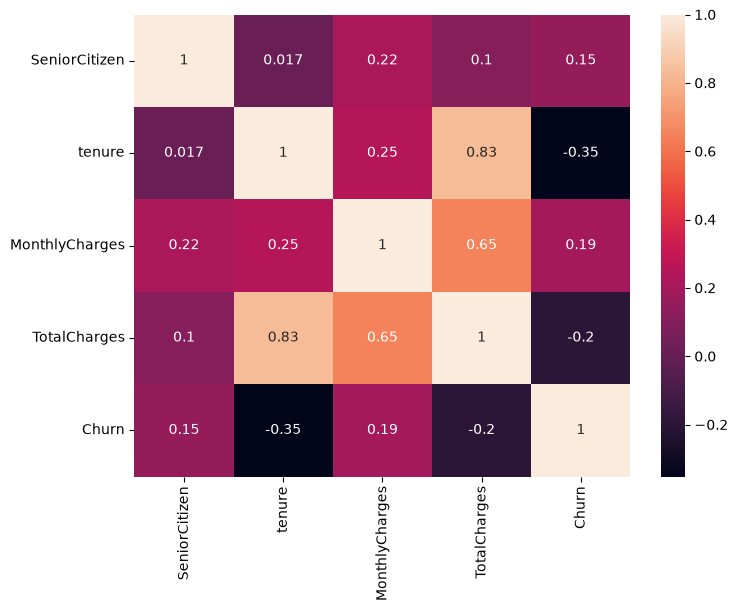

In [20]:
plt.figure(figsize=(8,6))
sns.heatmap(df_cleaned.corr(numeric_only=True),annot=True)

In [21]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [22]:
from sklearn.preprocessing import (OneHotEncoder, LabelEncoder, StandardScaler)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb 

In [23]:
X = df_cleaned.drop(columns=['Churn','customerID'])
y = df_cleaned['Churn']

In [24]:
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60


In [25]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [27]:
X_train.shape

(4718, 19)

In [28]:
y_train.shape

(4718,)

In [29]:
numeric_feature = ['tenure','MonthlyCharges','TotalCharges']
cat_feature = ['gender','Partner','Dependents','PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [30]:
ct = ColumnTransformer([
    ("num",StandardScaler(),numeric_feature),
    ("cat",OneHotEncoder(handle_unknown="ignore"),cat_feature),
    ("pass",'passthrough',['SeniorCitizen'])
])

In [31]:
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

In [32]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,f1_score

from sklearn.model_selection import cross_val_score

results = []

model_dict = {

    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),

    "RandomForestClassifier": RandomForestClassifier(random_state=42),

    "XGB": xgb.XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}

for name, model in model_dict.items():

    # Train model
    model.fit(X_train, y_train)

    # Test prediction
    y_pred = model.predict(X_test)

    # Test Accuracy
    acc = accuracy_score(y_test, y_pred)

    # F1
    f1 = f1_score(y_test,y_pred)

    # Classification report
    cr = classification_report(y_test,y_pred)

    # Cross Validation
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    # Mean CV Accuracy
    cv_acc = cv_scores.mean()

    results.append({
        'model': name,
        'test_acc_score': acc,
        'cv_acc_score': cv_acc,
        'f1_score': f1,
        'Classification_report': cr
    })

print(results)


[{'model': 'DecisionTreeClassifier', 'test_acc_score': 0.7324731182795698, 'cv_acc_score': np.float64(0.7301836008411667), 'f1_score': 0.5008025682182986, 'Classification_report': '              precision    recall  f1-score   support\n\n           0       0.81      0.82      0.82      1697\n           1       0.50      0.50      0.50       628\n\n    accuracy                           0.73      2325\n   macro avg       0.66      0.66      0.66      2325\nweighted avg       0.73      0.73      0.73      2325\n'}, {'model': 'RandomForestClassifier', 'test_acc_score': 0.7888172043010753, 'cv_acc_score': np.float64(0.7840207505796501), 'f1_score': 0.5524156791248861, 'Classification_report': '              precision    recall  f1-score   support\n\n           0       0.82      0.90      0.86      1697\n           1       0.65      0.48      0.55       628\n\n    accuracy                           0.79      2325\n   macro avg       0.74      0.69      0.71      2325\nweighted avg       0.7

In [33]:
results = pd.DataFrame(results)
results_sorted = results.sort_values(by=['cv_acc_score','f1_score'],ascending=False)
display(results_sorted)

,model,test_acc_score,cv_acc_score,f1_score,Classification_report
1,RandomForestClassifier,0.788817,0.784021,0.552416,precision recall f1-score ...
2,XGB,0.792688,0.771936,0.588737,precision recall f1-score ...
0,DecisionTreeClassifier,0.732473,0.730184,0.500803,precision recall f1-score ...


In [34]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

from sklearn.model_selection import cross_val_score


results = []

model_dict = {

    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),

    "RandomForestClassifier": RandomForestClassifier(random_state=42),

    "XGB": xgb.XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}


for name, model in model_dict.items():

    print("\n" + "="*70)
    print(f"MODEL: {name}")
    print("="*70)

    # Train model
    model.fit(X_train, y_train)

    # Test prediction
    y_pred = model.predict(X_test)

    # ---------------------------------------------------
    # Accuracy
    # ---------------------------------------------------

    acc = accuracy_score(y_test, y_pred)

    # ---------------------------------------------------
    # F1 Score
    # ---------------------------------------------------

    f1 = f1_score(y_test, y_pred)

    # ---------------------------------------------------
    # Confusion Matrix
    # ---------------------------------------------------

    cm = confusion_matrix(y_test, y_pred)

    print("\nConfusion Matrix:")
    print(cm)

    # ---------------------------------------------------
    # Classification Report
    # ---------------------------------------------------

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # ---------------------------------------------------
    # Cross Validation
    # ---------------------------------------------------

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_acc = cv_scores.mean()

    print("CV Scores:", cv_scores)
    print("Mean CV Accuracy:", cv_acc)

    # ---------------------------------------------------
    # Store results
    # ---------------------------------------------------

    results.append({
        "model": name,
        "test_acc_score": acc,
        "cv_acc_score": cv_acc,
        "f1_score": f1
    })


# =======================================================
# Final Results
# =======================================================

print("\n\nFINAL MODEL COMPARISON")
print("="*70)

for result in results:
    print(result)


MODEL: DecisionTreeClassifier

Confusion Matrix:
[[1391  306]
 [ 316  312]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.82      0.82      1697
           1       0.50      0.50      0.50       628

    accuracy                           0.73      2325
   macro avg       0.66      0.66      0.66      2325
weighted avg       0.73      0.73      0.73      2325

CV Scores: [0.72563559 0.72457627 0.73411017 0.71898197 0.747614  ]
Mean CV Accuracy: 0.7301836008411667

MODEL: RandomForestClassifier

Confusion Matrix:
[[1531  166]
 [ 325  303]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1697
           1       0.65      0.48      0.55       628

    accuracy                           0.79      2325
   macro avg       0.74      0.69      0.71      2325
weighted avg       0.78      0.79      0.78      2325

CV Scores: [0.78283898 0.77860169 0.780

# CV

# GridSearchCV

In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# =========================================================
# Models
# =========================================================

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(random_state=42),

    "XGBoost": xgb.XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}


# =========================================================
# Parameter Grids
# =========================================================

param_grids = {

    "Decision Tree": {
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [5, 10, None],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "max_features": ["sqrt", "log2"]
    },

    "XGBoost": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.1],
        "subsample": [0.8, 1.0]
    }
}


# =========================================================
# GridSearchCV
# =========================================================

best_models = {}

for name in models:

    print(f"\n{'='*50}")
    print(f"Training {name}")
    print(f"{'='*50}")

    grid = GridSearchCV(
        estimator=models[name],
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    print("Best Parameters:")
    print(grid.best_params_)

    print("Best CV F1 Score:")
    print(grid.best_score_)


Training Decision Tree
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best Parameters:
{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV F1 Score:
0.576326222885221

Training Random Forest
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1 Score:
0.5691574170205964

Training XGBoost
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV F1 Score:
0.5664023814607665


# Hyperparameter tunning 

In [36]:
pipe = Pipeline([
    ("model",'passthrough')
])

In [ ]:
grid_param = [
    {"model":[DecisionTreeClassifier()]
     "model__crit"}
]